This file is for testing the analytical solutions of the Black-Scholes equation implemented in analytical.py.

In [1]:
import sys
import os

sys.path.append(os.path.abspath(".."))

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

from src.analytical import call_price, put_price

In [3]:
call = call_price(S0=100, K=100, T=1, r=0.05, sigma=0.2)
put = put_price(S0=100, K=100, T=1, r=0.05, sigma=0.2)

print(call)
print(put)

10.450583572185565
5.573526022256971


In [4]:
# Verifying put-call parity.
C = call 
P = put 
S = 100
K = 100
r = 0.05
T = 1


LHS = C - P
RHS = S - K * np.exp(-r * T)

np.isclose(LHS, RHS)

np.True_

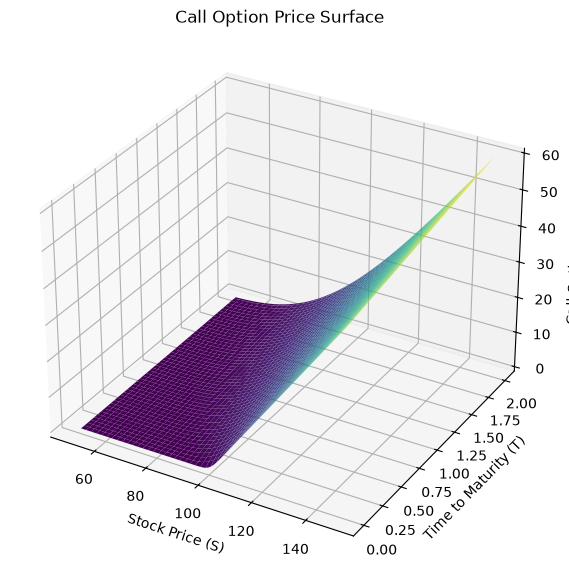

In [6]:
# Generating a call-price surface.

S_values = np.linspace(50, 150, 100)
T_values = np.linspace(0.01, 2, 100)

S_grid, T_grid = np.meshgrid(S_values, T_values)

C_grid = call_price(S0=S_grid, K=100, T=T_grid, r=0.05, sigma=0.2)

# Plotting the call-price surface.
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(S_grid, T_grid, C_grid, cmap='viridis')

ax.set_xlabel('Stock Price (S)')
ax.set_ylabel('Time to Maturity (T)')
ax.set_zlabel('Call Option Price (C)')
ax.set_title('Call Option Price Surface')
plt.show()